In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split
from scipy.stats import f_oneway
from sklearn.preprocessing import RobustScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import warnings
warnings.filterwarnings('ignore')

## Read Dataset

In [4]:
df = pd.read_csv('data/data_D.csv', index_col=0)

In [5]:
df.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x20c27,CUS_0xf64,June,NaN,32,478-73-8323,Doctor,56125.5,4875.125000,8,...,Standard,370.22,32.014182,28 Years and 10 Months,Yes,81.822857,182.06551022025016,High_spent_Medium_value_payments,473.62413320457887,Standard
1,0xc518,CUS_0x697f,March,Philh,39,367-66-5050,Entrepreneur,62148.0,NaN,9,...,Bad,2373.61,33.951720,16 Years and 6 Months,Yes,258.848861,195.3722153038279,High_spent_Small_value_payments,300.6789235920986,Poor
2,0x22663,CUS_0x7846,February,Paramadithak,45,282-14-9365,Accountant,88380.16,7471.013333,7,...,_,124.29,41.016763,NaN,Yes,129.723699,180.79874191787297,High_spent_Medium_value_payments,686.5788927990964,Standard
3,0x1ff7,CUS_0x3ef5,June,Robinsonl,32,259-09-9023,_______,7821.24,468.770000,8,...,Bad,2924.76,34.203026,10 Years and 2 Months,Yes,19.727923,39.93770264234067,Low_spent_Medium_value_payments,267.2113738653678,Standard
4,0x9a07,CUS_0x8fdf,June,Yeeo,18,312-56-4208,Scientist,107871.9,NaN,3,...,Standard,1005.83,27.237916,32 Years and 8 Months,No,227.241789,73.48570828760295,High_spent_Large_value_payments,820.9050026625811,Standard


Berdasarkan hasil, sudah terlihat bahwa data tidak clean dan memerlukan pembersihan

## Data Understanding

### Data Shape

In [5]:
n_row, n_col = df.shape
print(f'Number of rows: {n_row}')
print(f'Number of columns: {n_col}')

Number of rows: 25000
Number of columns: 28


Dataset memiliki 25000 baris dan 28 kolom.

### Dataset Informations

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 25000 entries, 0 to 24999
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        25000 non-null  object 
 1   Customer_ID               25000 non-null  object 
 2   Month                     25000 non-null  object 
 3   Name                      22471 non-null  object 
 4   Age                       25000 non-null  object 
 5   SSN                       25000 non-null  object 
 6   Occupation                25000 non-null  object 
 7   Annual_Income             25000 non-null  object 
 8   Monthly_Inhand_Salary     21173 non-null  float64
 9   Num_Bank_Accounts         25000 non-null  int64  
 10  Num_Credit_Card           25000 non-null  int64  
 11  Interest_Rate             25000 non-null  int64  
 12  Num_of_Loan               25000 non-null  object 
 13  Type_of_Loan              22120 non-null  object 
 14  Delay_from_

### Check Data Types

In [7]:
col_types = df.dtypes.reset_index()
col_types.columns = ['Column', 'Type']

print('Data type of each column:')
display(col_types)

Data type of each column:


,Column,Type
0,ID,object
1,Customer_ID,object
2,Month,object
3,Name,object
4,Age,object
5,SSN,object
6,Occupation,object
7,Annual_Income,object
8,Monthly_Inhand_Salary,float64
9,Num_Bank_Accounts,int64


Datatype pada beberapa kolom tidak sesuai dengan yang seharusnya yang menandakan adanya noise. Kolom yang menunjukkan adanya ketidaksesuaian tipe data adalah Age, Annual_Income, Num_of_Loan, Num_of_Delayed_Payment, Changed_Credit_Limit, Outstanding_Debt, Amount_invested_monthly, dan Monthly_Balance yang seharusnya berupa data numerik.

### Check Duplicate

In [8]:
dup = df.duplicated().sum()
print('Duplicated Row: ', dup)

Duplicated Row:  0


Tidak terdapat nilai duplikat pada dataset.

### Check Missing Value

In [9]:
df.isnull().sum()

ID                             0
Customer_ID                    0
Month                          0
Name                        2529
Age                            0
SSN                            0
Occupation                     0
Annual_Income                  0
Monthly_Inhand_Salary       3827
Num_Bank_Accounts              0
Num_Credit_Card                0
Interest_Rate                  0
Num_of_Loan                    0
Type_of_Loan                2880
Delay_from_due_date            0
Num_of_Delayed_Payment      1744
Changed_Credit_Limit           0
Num_Credit_Inquiries         497
Credit_Mix                     0
Outstanding_Debt               0
Credit_Utilization_Ratio       0
Credit_History_Age          2249
Payment_of_Min_Amount          0
Total_EMI_per_month            0
Amount_invested_monthly     1121
Payment_Behaviour              0
Monthly_Balance              309
Credit_Score                   0
dtype: int64

Terdapat missing values pada beberapa kolom seperti Name, Monthly_Inhand_Salary, Type_of_Loan, Num_of_Delayed_Payment, Num_Credit_Inquiries, Credit_History_Age, Amount_invested_monthly, dan Monthly_Balance.

### Check Numerical Variables

In [10]:
df.describe()

,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Delay_from_due_date,Num_Credit_Inquiries,Credit_Utilization_Ratio,Total_EMI_per_month
count,21173.000000,25000.000000,25000.000000,25000.000000,25000.000000,24503.000000,25000.000000,25000.000000
mean,4168.307097,16.865000,23.311840,70.358920,21.065360,26.939762,32.273187,1440.039648
std,3170.867622,114.767426,133.618787,458.469762,14.885855,189.253774,5.114177,8514.909613
min,303.645417,-1.000000,0.000000,1.000000,-5.000000,0.000000,20.000000,0.000000
25%,1625.265833,4.000000,4.000000,8.000000,10.000000,3.000000,28.059564,29.912485
50%,3080.353333,6.000000,5.000000,13.000000,18.000000,6.000000,32.331522,68.781136
75%,5927.527500,8.000000,7.000000,20.000000,28.000000,9.000000,36.475246,160.180388
max,15204.633333,1794.000000,1499.000000,5789.000000,67.000000,2553.000000,49.564519,82122.000000


Pada hasil analisis statistik deskriptif terdapat kolom yang memiliki rentang tidak wajar, yaitu Num_Bank_Accounts, Num_Credit_Card, Interest_Rate, Delay_from_due_date, Num_Credit_Inquiries, dan Total_EMI_per_month yang memiliki nilai minimum negatif dan nilai maximum yang sangat besar. 

### Check Categorical Variables

In [11]:
df.describe(exclude=np.number)

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Num_of_Loan,Type_of_Loan,Num_of_Delayed_Payment,Changed_Credit_Limit,Credit_Mix,Outstanding_Debt,Credit_History_Age,Payment_of_Min_Amount,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
count,25000,25000,25000,22471,25000,25000,25000,25000,25000,22120,23256,25000,25000,25000,22751,25000,23879,25000,24691,25000
unique,25000,11199,8,9014,548,11024,16,12749,131,5690,241,3395,4,11187,403,3,22751,7,24689,3
top,0x20c27,CUS_0x8727,August,Deepa Seetharamanm,27,#F%$D@*&8,_______,29020.78,3,Not Specified,17,_,Standard,967.75,19 Years and 5 Months,Yes,__10000__,Low_spent_Small_value_payments,__-333333333333333333333333333__,Standard
freq,1,8,3189,16,708,1397,1735,8,3610,341,1367,523,9097,11,127,13041,1092,6331,3,13305


Pada hasil analisis deskriptif pada kolom kategorikal menunjukkan adanya nilai berupa simbol acak dan string tidak valid. Hasil ini mengindikasikan bahwa ketidaksesuaian tipe data yang sebelumnya telah diidentifikasi disebabkan oleh string pada kolom tersebut. 

In [12]:
categorical_col = df.select_dtypes(exclude=['int64', 'float64']).columns

In [13]:
for col in categorical_col:
  print('Total Unique Values: ', df[col].nunique())
  print(df[col].value_counts(dropna=False), "\n")

Total Unique Values:  25000
ID
0x20c27    1
0x21529    1
0x1f806    1
0x216a8    1
0x1c080    1
          ..
0x22ce     1
0x4a32     1
0x21b41    1
0x9909     1
0x10d0c    1
Name: count, Length: 25000, dtype: int64 

Total Unique Values:  11199
Customer_ID
CUS_0x8727    8
CUS_0x5e3d    7
CUS_0x6590    7
CUS_0xd40     7
CUS_0x2950    6
             ..
CUS_0xac60    1
CUS_0x9e6a    1
CUS_0x846e    1
CUS_0x1c89    1
CUS_0x2346    1
Name: count, Length: 11199, dtype: int64 

Total Unique Values:  8
Month
August      3189
June        3167
January     3154
May         3152
April       3137
July        3112
February    3104
March       2985
Name: count, dtype: int64 

Total Unique Values:  9014
Name
NaN                   2529
Deepa Seetharamanm      16
Stevex                  15
Jessica Wohlt           14
Alexei Oreskovics       13
                      ... 
Henryn                   1
Edd                      1
Chrisc                   1
Williamso                1
Chanu                    1
N

Hasil analisis lebih lanjut menunjukkan bahwa beberapa kolom memiliki format dan karakter asing. Selain itu, pada kolom Payment_of_Min_Amount ditemukan nilai "NM" yang merepresentasikan Not Mentioned. Oleh karena itu, nilai "NM" akan diperlakukan sebagai missing value.

In [ ]:
#mencari data yang bukan angka menggunakan regex
noisy_numeric_cols = ['Age', 'Annual_Income', 'Num_of_Loan', 'Num_of_Delayed_Payment',
                       'Changed_Credit_Limit', 'Outstanding_Debt',
                       'Amount_invested_monthly', 'Monthly_Balance']

for col in noisy_numeric_cols:
    non_numeric_mask = ~df[col].astype(str).str.match(r'^-?\d+\.?\d*$') #mengubah menjadi string dan memeriksa angka menggunakan regex
    print(df[col][non_numeric_mask].value_counts(dropna=False).head())
    print()

Age
24_    45
26_    44
29_    44
41_    43
36_    42
Name: count, dtype: int64

Annual_Income
7830.03_     3
10024.25_    3
8927.89_     3
28131.62_    3
23987.59_    3
Name: count, dtype: int64

Num_of_Loan
2_    189
4_    184
3_    173
0_    132
1_    120
Name: count, dtype: int64

Num_of_Delayed_Payment
NaN    1744
19_      49
10_      45
18_      42
20_      41
Name: count, dtype: int64

Changed_Credit_Limit
_    523
Name: count, dtype: int64

Outstanding_Debt
1179.95_    2
761.18_     2
923.5_      2
629.16_     2
1180.91_    1
Name: count, dtype: int64

Amount_invested_monthly
NaN          1121
__10000__    1092
Name: count, dtype: int64

Monthly_Balance
NaN                                 309
__-333333333333333333333333333__      3
Name: count, dtype: int64



Hasil menunjukkan adanya noise berupa underscore pada kolom-kolom tersebut sehingga tipe data yang seharusnya numerik menjadi object.

### Check Inconsistency Customer Data

In [ ]:
#mengecek data yang memiliki occupation tidak valid 
sample_cid = df[df['Occupation'] == '_______']['Customer_ID'].iloc[0]
df[df['Customer_ID'] == sample_cid][['Month', 'Name', 'Age', 'Occupation']]

,Month,Name,Age,Occupation
3,June,Robinsonl,32,_______
4356,August,Robinsonl,32,Doctor
11512,January,Robinsonl,-500,Doctor
19228,March,Robinsonl,32,Doctor
20198,April,Robinsonl,32,Doctor


Customer dengan occupation `_______` dengan Customer_ID yang sama memiliki Age dan Occupation yang berbeda. Hal ini menandakan adanya inkonsistensi pada data customer.

### Check Target Imbalance

In [145]:
df['Credit_Score'].value_counts(normalize=True)

Credit_Score
Standard    0.53220
Poor        0.28924
Good        0.17856
Name: proportion, dtype: float64

Berdasarkan hasil, nilai target klasifikasi menunjukkan ketidakseimbangan. Kelas 'Good' dan kelas 'Poor' lebih rendah dibandingkan dengan kelas 'Standard'. Hal ini dapat memengaruhi hasil evaluasi model.

**Kesimpulan Identifikasi Masalah**
- Tipe data: `Age`, `Annual_Income`, `Num_of_Loan`, `Num_of_Delayed_Payment`, `Changed_Credit_Limit`, `Outstanding_Debt`, `Amount_invested_monthly`, `Monthly_Balance`

- Missing value: `Name`, `Monthly_Inhand_Salary`, `Type_of_Loan`, `Num_of_Delayed_Payment`, `Num_Credit_Inquiries`, `Credit_History_Age`, `Amount_invested_monthly`, `Monthly_Balance`

- Outlier: `Num_Bank_Accounts`, `Num_Credit_Card`, `Interest_Rate`, `Delay_from_due_date`, `Num_Credit_Inquiries`, `Total_EMI_per_month`

- Format `angka_`: `Age`, `Annual_Income`, `Num_of_Loan`, `Num_of_Delayed_Payment`, `Outstanding_Debt`

- Placeholder `_`: `Changed_Credit_Limit`, `Credit_Mix`

- Placeholder `_______`: `Occupation`

- Format `__value__`: `Amount_invested_monthly`, `Monthly_Balance`

- String acak: `SSN`, `Payment_Bahaviour`

- Perlu parsing menjadi numerik: `Credit_History_Age`

- Perlakuan missing value: `NM` pada `Payment_of_Min_Amount`

- Inconsistency nilai customer dengan Occupation `_______`

- Imbalance pada target

## Split Dataset

Membagi dataset untuk train data dan test data dengan 80% untuk train dan 20% untuk test.

In [18]:
X = df.drop(columns=['Credit_Score'])
y = df['Credit_Score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [19]:
print(f'Train set shape: {X_train.shape}')
print(f'Test set shape: {X_test.shape}')

Train set shape: (20000, 27)
Test set shape: (5000, 27)


Train data terdiri dari 20000 baris dan test data terdiri dari 5000 baris.

## Visualisasi Distribusi Data

### Distribusi Target Credit Score

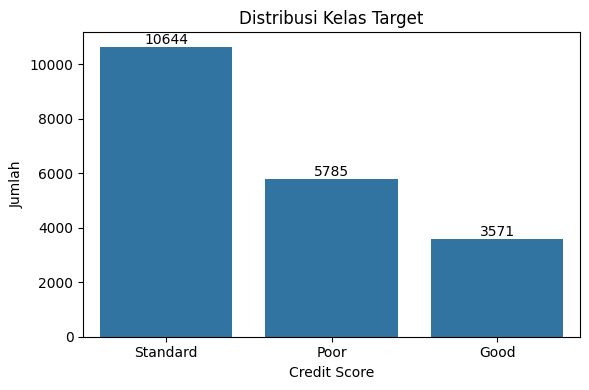

In [20]:
plt.figure(figsize=(6,4))
ax = sns.countplot(x=y_train, order=y_train.value_counts().index)
plt.title('Distribusi Kelas Target')
plt.xlabel('Credit Score')
plt.ylabel('Jumlah')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x()+p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.tight_layout()
plt.show()

Plot menunjukkan kelas 'Standard' jauh lebih banyak dibandingkan kedua kelas lainnya yaitu kelas 'Poor' dan 'Good'. 

### Distribusi Variabel Numerik

In [21]:
#convert variabel numerik yang menjadi object untuk visualisasi
def convert_to_numeric(series):
    return pd.to_numeric(series.astype(str).str.replace(r'[^\d.-]', '').replace('nan', np.nan), errors='coerce')

In [22]:
visualize_cols = X_train.copy()

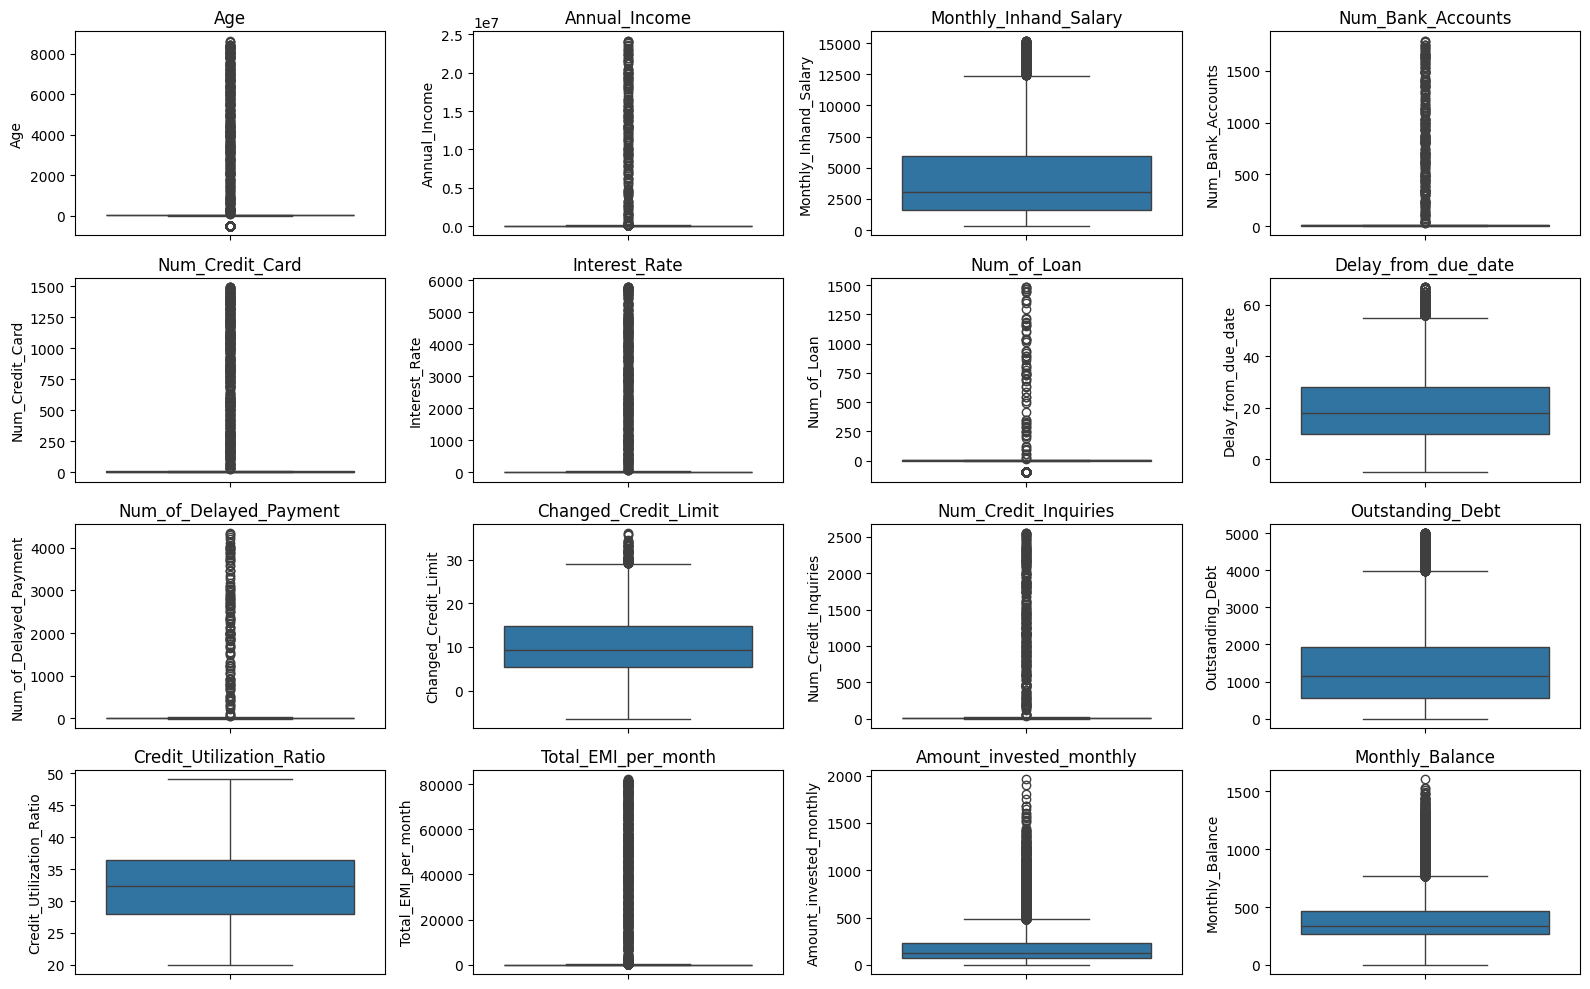

In [23]:
for col in ['Age', 'Annual_Income', 'Num_of_Loan', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Outstanding_Debt', 'Amount_invested_monthly', 'Monthly_Balance']:
    visualize_cols[col] = convert_to_numeric(visualize_cols[col])

fig, axes = plt.subplots(4, 4, figsize=(16, 10))
cols_to_plot = ['Age', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Monthly_Balance']
for ax, col in zip(axes.flatten(), cols_to_plot):
    sns.boxplot(y=visualize_cols[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Berdasarkan boxplot, terlihat jelas bahwa semua kolom memiliki outlier kecuali kolom `Credit_Utilization_Ratio`. `Age` dan `Num_of_Loan` memiliki nilai negatif dan outlier yang sangat jauh dari distribusi data, sementara `Annual_Income`, `Num_Bank_Account`, `Num_Credit_Card`, `Interest_Rate`, `Num_of_Delayed_Payment`, `Num_Credit_Inquiries`, `Total_EMI_per_month`, `Amount_invested_monthly`, `Monthly_Balance` memiliki nilai outlier yang sangat jauh dari mayoritas data. Hal ini merupakan noise, bukan variasi alami dari data.

### Distribusi Variabel Kategorikal

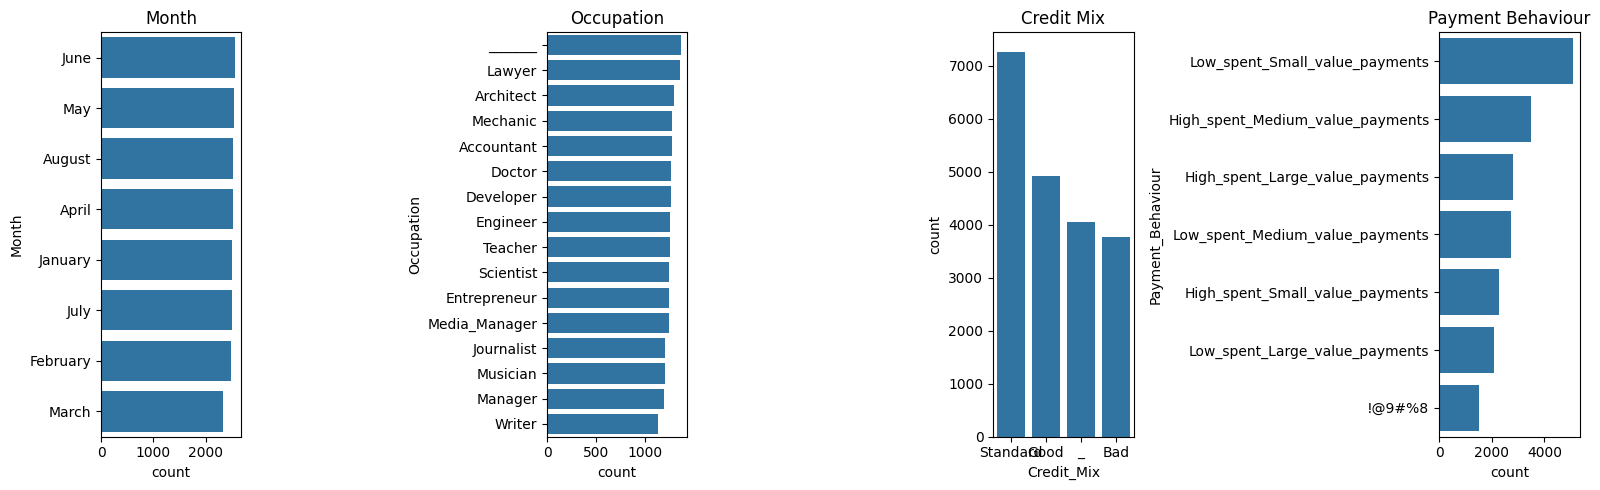

In [152]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
sns.countplot(y=X_train['Month'], order=X_train['Month'].value_counts().index, ax=axes[0])
axes[0].set_title('Month')

sns.countplot(y=X_train['Occupation'], order=X_train['Occupation'].value_counts().index, ax=axes[1])
axes[1].set_title('Occupation')

sns.countplot(x=X_train['Credit_Mix'], order=X_train['Credit_Mix'].value_counts().index, ax=axes[2])
axes[2].set_title('Credit Mix')
    
sns.countplot(y=X_train['Payment_Behaviour'], order=X_train['Payment_Behaviour'].value_counts().index, ax=axes[3])
axes[3].set_title('Payment Behaviour')
plt.tight_layout()
plt.show()

Berdasarkan plot, terlihat bahwa pada `Occupation`, value `_______` merupakan mayoritas dari data dan akan diperlakukan sebagai missing value, pada `Credit_Mix`, terdapat value `_` yang akan diperlakukan sebagai missing value, dan pada Payment_Behavior, terdapat value string acak yang akan diperlakukan sebagai missing value.

## Data Cleaning

**Cleaning noise yang dilakukan**
- Mengubah kolom numerik yang memiliki noise berupa underscore menjadi numerik asli.
- Mengganti placeholder dengan string acak dan underscore menjadi `Nan`.
- Melakukan parsing pada Credit_History_Age menjadi jumlah bulan (numerik).
- Memperbaiki inkonsisten data customer `Age` dan `Occupation` untuk Customer_ID yang sama.
- Mengubah outlier negatif menjadi `Nan`.
- Melakukan capping pada outlier dengan nilai yang sangat besar.
- Mengubah nilai `NM` pada `Payment_of_Min_Amount` menjadi `Nan`.


### Membersihkan kolom numerik dari noise

In [24]:
#fungsi untuk membersihkan string dari kolom numerik
def clean_numeric_string(series):
    s = series.astype(str)
    s = s.replace(['_', 'nan', 'NaN', ''], np.nan)
    s = s.str.replace('_', '', regex=False)
    s = s.str.strip()
    return pd.to_numeric(s, errors='coerce')

### Parsing `Credit_History_Age`

In [25]:
#fungsi untuk mengubah kolom credit history age menjadi bulan
def parse_credit_history_age(val):
    if pd.isna(val):
        return np.nan
    m = re.match(r'(\d+)\s*Years?\s*and\s*(\d+)\s*Months?', str(val))
    if m:
        return int(m.group(1)) * 12 + int(m.group(2))
    return np.nan

### Capping pada kolom yang memiliki outlier

Karena dataset memiliki outlier yang sangat ekstrem, maka harus dibatasi menggunakan cap threshold (batas atas) berdasarkan persentil ke 99. Threshold ini dipakai untuk capping outlier.

In [26]:
cap_cols = ['Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Num_of_Delayed_Payment', 'Num_Credit_Inquiries', 'Total_EMI_per_month', 'Annual_Income']

def fit_cap_thresholds(X):
    thresholds = {}
    X_temp = X.copy()
    noisy_numeric_cols = ['Age', 'Annual_Income', 'Num_of_Loan', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Outstanding_Debt', 'Amount_invested_monthly', 'Monthly_Balance']
    for col in noisy_numeric_cols:
        X_temp[col] = clean_numeric_string(X_temp[col])
    for col in cap_cols:
        thresholds[col] = X_temp[col].quantile(0.99)
    return thresholds


### Clean data dari noise

In [27]:
def clean_data(X, cap_thresholds, customer_mode_map=None, fit_customer_map=False):
    X = X.copy()

    #membersihkan kolom numerik yang memiliki noise string
    noisy_numeric_cols = ['Age', 'Annual_Income', 'Num_of_Loan', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Outstanding_Debt', 'Amount_invested_monthly', 'Monthly_Balance']
    for col in noisy_numeric_cols:
        X[col] = clean_numeric_string(X[col])

    #replace placeholder aneh pada kolom kategorikal dengan NaN
    X['Occupation'] = X['Occupation'].replace('_______', np.nan)
    X['Credit_Mix'] = X['Credit_Mix'].replace('_', np.nan)
    X['Payment_Behaviour'] = X['Payment_Behaviour'].replace('!@9#%8', np.nan)
    X['SSN'] = X['SSN'].replace('#F%$D@*&8', np.nan)
    X['Payment_of_Min_Amount'] = X['Payment_of_Min_Amount'].replace('NM', np.nan)

    #parsing credit history age dari format "X Years and Y Months" ke total bulan
    X['Credit_History_Age_Months'] = X['Credit_History_Age'].apply(parse_credit_history_age)
    X = X.drop(columns=['Credit_History_Age'])

    #memperbaiki inkonsistensi Age & Occupation per Customer_ID 
    if fit_customer_map:
        customer_mode_map = {
            'Age': X.groupby('Customer_ID')['Age'].apply(lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan),
            'Occupation': X.groupby('Customer_ID')['Occupation'].apply(lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan),
        }
    if customer_mode_map is not None:
        X['Age'] = X['Customer_ID'].map(customer_mode_map['Age']).combine_first(X['Age'])
        X['Occupation'] = X['Customer_ID'].map(customer_mode_map['Occupation']).combine_first(X['Occupation'])

    #mengubah nilai numerik yang tidak masuk akal menjadi NaN
    X.loc[(X['Age'] < 0) | (X['Age'] > 100), 'Age'] = np.nan
    X.loc[X['Num_Bank_Accounts'] < 0, 'Num_Bank_Accounts'] = np.nan
    X.loc[X['Num_of_Loan'] < 0, 'Num_of_Loan'] = np.nan
    X.loc[X['Delay_from_due_date'] < 0, 'Delay_from_due_date'] = np.nan
    X.loc[X['Num_of_Delayed_Payment'] < 0, 'Num_of_Delayed_Payment'] = np.nan
    X.loc[X['Amount_invested_monthly'] >= 10000, 'Amount_invested_monthly'] = np.nan
    X.loc[X['Monthly_Balance'].abs() > 1e6, 'Monthly_Balance'] = np.nan

    #capping nilai numerik ekstrem berdasarkan threshold yang sudah ditentukan
    for col, cap in cap_thresholds.items():
        X[col] = np.where(X[col] > cap, cap, X[col])

    #drop kolom identifier yang tidak relevan sebagai fitur
    drop_cols = ['ID', 'Customer_ID', 'Name', 'SSN', 'Month', 'Type_of_Loan']
    X = X.drop(columns=drop_cols)

    if fit_customer_map:
        return X, customer_mode_map
    return X

In [28]:
#threshold capping berdaasarkan distribusi train set 
cap_thresholds = fit_cap_thresholds(X_train)

X_train_clean, customer_mode_map = clean_data(X_train, cap_thresholds, fit_customer_map=True)
X_test_clean = clean_data(X_test, cap_thresholds, customer_mode_map=customer_mode_map)

### Setelah dibersihkan dari noise

In [29]:
print("X_train_clean shape:", X_train_clean.shape)
print("X_test_clean shape :", X_test_clean.shape)

X_train_clean shape: (20000, 21)
X_test_clean shape : (5000, 21)


In [30]:
print("Missing values (train) setelah cleaning:")
print(X_train_clean.isnull().sum()[X_train_clean.isnull().sum() > 0].sort_values(ascending=False))

Missing values (train) setelah cleaning:
Credit_Mix                   4056
Monthly_Inhand_Salary        3073
Payment_of_Min_Amount        2373
Credit_History_Age_Months    1779
Amount_invested_monthly      1761
Num_of_Delayed_Payment       1534
Payment_Behaviour            1529
Num_of_Loan                   745
Changed_Credit_Limit          432
Num_Credit_Inquiries          398
Occupation                    306
Age                           279
Monthly_Balance               254
Delay_from_due_date           114
Num_Bank_Accounts               4
dtype: int64


Missing value bertambah karena proses clean_data yang mengubah nilai tidak valid menjadi missing value.

In [31]:
col_types = X_train_clean.dtypes.reset_index()
col_types.columns = ['Column', 'Type']

print('Data type of each column:')
display(col_types)

Data type of each column:


,Column,Type
0,Age,float64
1,Occupation,object
2,Annual_Income,float64
3,Monthly_Inhand_Salary,float64
4,Num_Bank_Accounts,float64
5,Num_Credit_Card,float64
6,Interest_Rate,float64
7,Num_of_Loan,float64
8,Delay_from_due_date,float64
9,Num_of_Delayed_Payment,float64


Data type kolom numerik yang semulanya object, menjadi sudah sesuai.

In [32]:
X_train_clean.describe()

,Age,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance,Credit_History_Age_Months
count,19721.000000,20000.000000,16927.000000,19996.000000,20000.000000,20000.000000,19255.000000,19886.000000,18466.000000,19568.000000,19602.000000,20000.000000,20000.000000,20000.000000,18239.000000,19746.000000,18221.000000
mean,33.431063,52482.687903,4176.297059,10.486897,19.997100,58.481400,3.532537,21.134567,13.488519,10.407224,18.596779,1423.768838,32.237465,1293.034012,194.245779,403.078894,222.060809
std,10.778299,43749.738158,3180.038582,45.862350,104.108627,330.082991,2.462446,14.734768,6.293439,6.784473,107.038639,1153.930234,5.122524,7394.892094,198.994714,214.313727,99.966922
min,14.000000,7005.930000,319.556250,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,-6.440000,0.000000,0.230000,20.000000,0.000000,0.000000,0.688299,2.000000
25%,25.000000,19440.133750,1619.648333,3.000000,4.000000,8.000000,2.000000,10.000000,9.000000,5.380000,3.000000,568.817500,28.009518,29.828377,71.403352,270.969821,145.000000
50%,33.000000,37360.940000,3081.902500,6.000000,6.000000,13.000000,3.000000,18.000000,14.000000,9.370000,6.000000,1156.950000,32.300707,68.498987,126.978781,337.950363,220.000000
75%,42.000000,72588.990000,5938.136667,7.000000,7.000000,20.000000,5.000000,28.000000,18.000000,14.880000,9.000000,1936.410000,36.449144,159.809637,234.885004,468.086720,305.000000
max,56.000000,266033.310000,15204.633333,441.000000,884.100000,2874.030000,9.000000,67.000000,27.000000,36.090000,981.980000,4998.070000,49.064277,56747.460000,1961.218850,1602.040519,404.000000


In [33]:
X_train_clean.describe(exclude=np.number)

,Occupation,Credit_Mix,Payment_of_Min_Amount,Payment_Behaviour
count,19694,15944,17627,18471
unique,15,3,2,6
top,Lawyer,Standard,Yes,Low_spent_Small_value_payments
freq,1435,7263,10414,5084


In [34]:
categorical_col = X_train_clean.select_dtypes(exclude=['int64', 'float64']).columns
for col in categorical_col:
  print('Total Unique Values: ', X_train_clean[col].nunique())
  print(X_train_clean[col].value_counts(dropna=False), "\n")

Total Unique Values:  15
Occupation
Lawyer           1435
Architect        1367
Doctor           1350
Mechanic         1344
Accountant       1340
Developer        1331
Engineer         1323
Scientist        1312
Media_Manager    1308
Teacher          1306
Entrepreneur     1299
Journalist       1266
Musician         1258
Manager          1258
Writer           1197
NaN               306
Name: count, dtype: int64 

Total Unique Values:  3
Credit_Mix
Standard    7263
Good        4923
NaN         4056
Bad         3758
Name: count, dtype: int64 

Total Unique Values:  2
Payment_of_Min_Amount
Yes    10414
No      7213
NaN     2373
Name: count, dtype: int64 

Total Unique Values:  6
Payment_Behaviour
Low_spent_Small_value_payments      5084
High_spent_Medium_value_payments    3477
High_spent_Large_value_payments     2809
Low_spent_Medium_value_payments     2734
High_spent_Small_value_payments     2270
Low_spent_Large_value_payments      2097
NaN                                 1529
Name: count

Unique value sudah tidak terdapat string aneh dan nilai yang tidak valid

## Feature Selection

### Check Korelasi antar Numerik

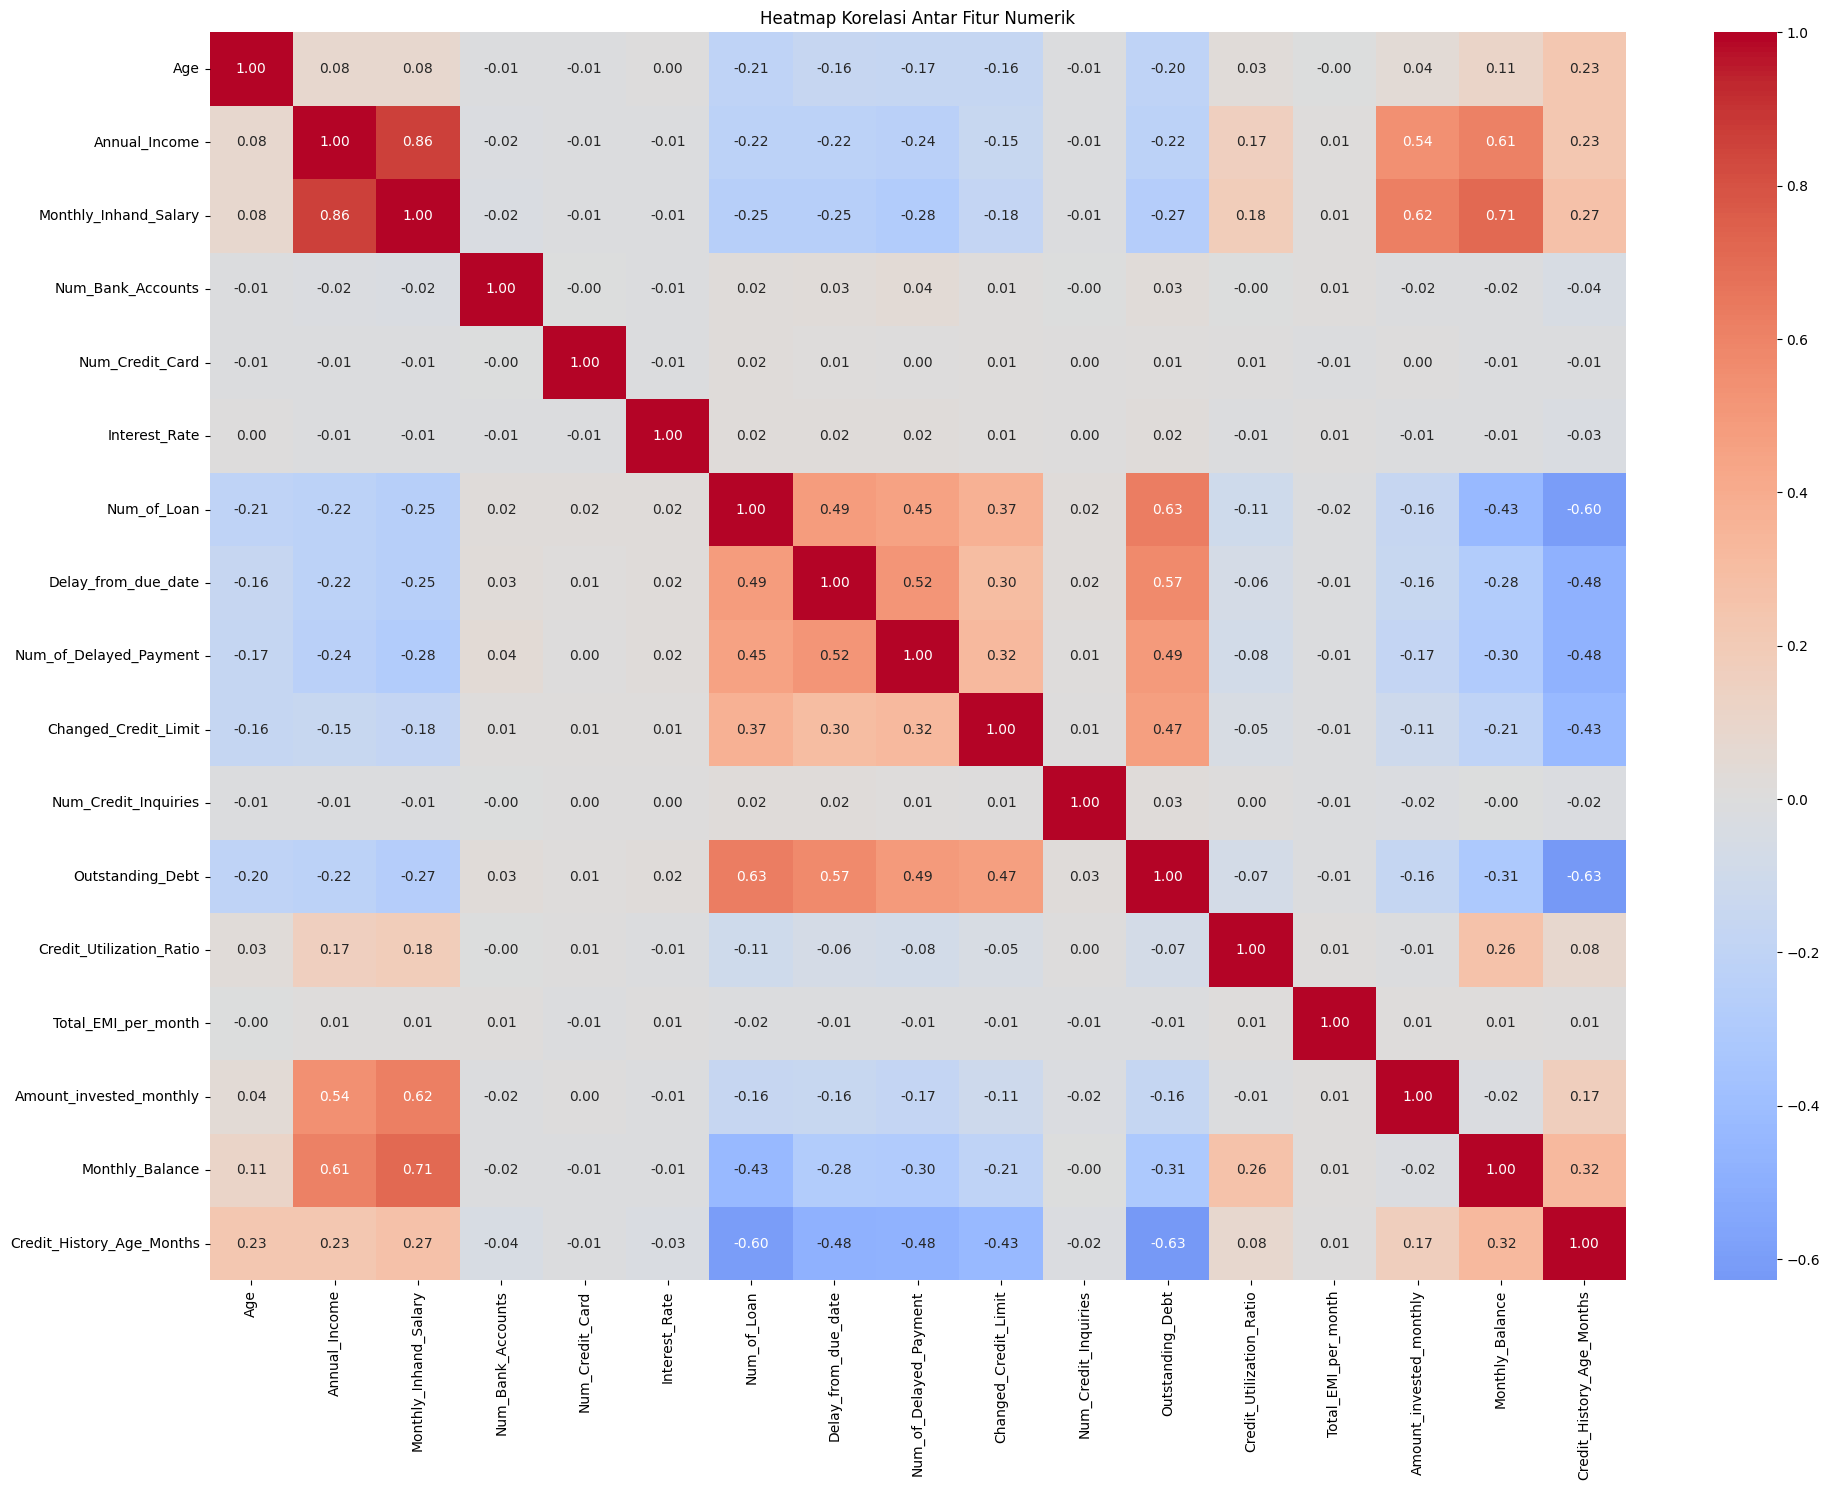

In [35]:
plt.figure(figsize=(20, 15))
num_cols_corr = X_train_clean.select_dtypes(include=[np.number]).columns
corr = X_train_clean[num_cols_corr].corr()

sns.heatmap(
    corr,
    annot=True,     
    fmt='.2f',   
    cmap='coolwarm',
    center=0
)

plt.title('Heatmap Korelasi Antar Fitur Numerik')
plt.tight_layout()
plt.show()

Berdasarkan hasil heatmap, terlihat bahwa `Annual_Income` dan `Monthly_Inhand_Salary` memiliki korelasi yang sangat tinggi yaitu sekitar 0.86. Nilai korelasi yang sangat tinggi ini menunjukkan adanya kemungkinan multikolinearitas. Oleh karena itu, salah satu dari variabel tersebut harus di drop untuk mencegah multikolinearitas. 

In [36]:
X_train_clean.columns

Index(['Age', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary',
       'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan',
       'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
       'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt',
       'Credit_Utilization_Ratio', 'Payment_of_Min_Amount',
       'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour',
       'Monthly_Balance', 'Credit_History_Age_Months'],
      dtype='object')

In [37]:
#menghitung p-value untuk membandingkan distribusi Annual_Income dan Monthly_Inhand_Salary antar kelas Credit_Score
train_df = X_train_clean.copy()
train_df['Credit_Score'] = y_train

for col in ['Annual_Income', 'Monthly_Inhand_Salary']:
    groups = [
        train_df[train_df['Credit_Score'] == score][col].dropna()
        for score in train_df['Credit_Score'].unique()
    ]

    stat, p = f_oneway(*groups)

    print(f"\n{col}")
    print(f"F-statistic : {stat:.4f}")
    print(f"p-value     : {p:.4e}")


Annual_Income
F-statistic : 393.4176
p-value     : 2.6105e-168

Monthly_Inhand_Salary
F-statistic : 423.6545
p-value     : 2.9295e-180


Hasil menunjukkan kedua fitur sangat signifikan terhadap target. Namun, `Annual_Income` harus di drop karena memiliki p-value yang lebih besar dibandingkan `Monthly_Inhand_Salary`. Artinya `Monthly_Inhand_Salary` lebih kuat dibandingkan `Annual_Income`.

In [38]:
feature_to_drop = ['Annual_Income']

X_train_fin = X_train_clean.drop(columns=feature_to_drop)
X_test_fin = X_test_clean.drop(columns=feature_to_drop)

print(list(X_train_fin.columns))

['Age', 'Occupation', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance', 'Credit_History_Age_Months']


## Encoding

In [39]:
X_train_fin

,Age,Occupation,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_History_Age_Months
17041,NaN,Engineer,944.305417,6.0,4.0,9.0,4.0,29.0,8.0,13.60,0.0,Standard,1225.88,26.099097,NaN,33.687913,32.296644,Low_spent_Small_value_payments,318.445984,271.0
4656,43.0,Writer,2022.350833,4.0,7.0,9.0,1.0,17.0,20.0,1.68,1.0,Standard,1476.59,37.925236,NaN,22.082560,39.931908,High_spent_Large_value_payments,380.220615,226.0
2364,52.0,Journalist,1721.870000,4.0,6.0,20.0,2.0,25.0,15.0,11.04,3.0,Standard,8.20,30.249331,No,28.446055,NaN,Low_spent_Small_value_payments,354.345723,270.0
22193,18.0,Engineer,1424.849167,9.0,9.0,19.0,NaN,36.0,18.0,20.04,9.0,Bad,2994.45,33.418794,Yes,59.385697,NaN,Low_spent_Small_value_payments,283.472131,114.0
6249,19.0,Engineer,1285.586667,6.0,8.0,15.0,5.0,19.0,9.0,8.62,7.0,Standard,2674.44,35.913442,Yes,38.516203,125.310819,Low_spent_Medium_value_payments,244.731644,155.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
551,30.0,Manager,962.458333,7.0,7.0,19.0,9.0,35.0,21.0,26.96,10.0,Bad,4496.77,24.879337,Yes,79.506552,84.557811,Low_spent_Small_value_payments,222.181470,143.0
3610,43.0,Media_Manager,NaN,3.0,5.0,8.0,0.0,22.0,14.0,5.22,3.0,Standard,1141.68,34.027958,No,0.000000,364.523051,NaN,1005.517949,230.0
12912,18.0,Journalist,5481.745000,4.0,4.0,2.0,4.0,15.0,5.0,4.21,0.0,Good,317.74,41.336706,No,227.982533,104.894529,High_spent_Large_value_payments,455.297438,305.0
11839,39.0,Accountant,6025.336667,6.0,3.0,13.0,1.0,12.0,12.0,NaN,1.0,Standard,359.14,24.966532,Yes,58.016785,45.184323,High_spent_Large_value_payments,739.332559,317.0


In [40]:
num_feat = X_train_fin.select_dtypes(include=['int64', 'float64']).columns.tolist()

ohe_feat = X_train_fin.select_dtypes(include=['object', 'category']).drop(columns=['Credit_Mix', 'Payment_Behaviour'], errors='ignore').columns.tolist()

ord_feat = ['Credit_Mix', 'Payment_Behaviour']

In [41]:
print("OneHot:", ohe_feat)
print("Ordinal:", ord_feat)
print("Numeric:", num_feat)

OneHot: ['Occupation', 'Payment_of_Min_Amount']
Ordinal: ['Credit_Mix', 'Payment_Behaviour']
Numeric: ['Age', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Monthly_Balance', 'Credit_History_Age_Months']


Pada kolom ohe, akan digunakan OneHotEncoding karena value di dalamnya tidak memiliki urutan, sedangkan pada kolom ordinal, akan digunakan OrdinalEncoding karena value di dalamnya memiliki urutan. Pada kolom numerik, scaling akan dilakukan dengan robust scaler karena distribusi data masih terdapat outllier dan skewed. Untuk handle missing value pada kolom kategorikal akan digunakan 'modus' dan pada kolom numerikal akan digunakan 'median'.

In [42]:
#mapping target
mapping_score = {'Poor': 0, 'Standard': 1, 'Good': 2}
y_train_fin = y_train.map(mapping_score)
y_test_fin = y_test.map(mapping_score)

In [43]:
#order untuk ordinal encoding
credit_mix_order = ['Bad', 'Standard', 'Good']
payment_behaviour_order = [
    'Low_spent_Small_value_payments',
    'Low_spent_Medium_value_payments',
    'Low_spent_Large_value_payments',
    'High_spent_Small_value_payments',
    'High_spent_Medium_value_payments',
    'High_spent_Large_value_payments'
]

Pada kolom numerik, missing value akan diisi dengan median mengingat data memiliki outlier selain itu juga dilakukan scaling menggunakan robust karena data memiliki outlier dan bukan normal distributed.   
Pada kolom kategorik, missing value diisi dengan modus.

In [44]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

ohe_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

ordinal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=[credit_mix_order, payment_behaviour_order]))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_feat),
        ('ohe', ohe_transformer, ohe_feat),
        ('ord', ordinal_transformer, ord_feat)
    ],
    remainder='drop'
)

In [45]:
preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', RobustScaler())]),
                                 ['Age', 'Monthly_Inhand_Salary',
                                  'Num_Bank_Accounts', 'Num_Credit_Card',
                                  'Interest_Rate', 'Num_of_Loan',
                                  'Delay_from_due_date',
                                  'Num_of_Delayed_Payment',
                                  'Changed_Credit_Limit',
                                  'Num_Credit_Inquiries', 'Outstanding_Debt',
                                  'Credit_Uti...
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('ordinal',
                                                  OrdinalEncoder(categories=[['Bad',
                                                                              'Standard',
                                                                              'Good'],
                                                                             ['Low_spent_Small_value_payments',
                                                                              'Low_spent_Medium_value_payments',
                                                                              'Low_spent_Large_value_payments',
                                                                              'High_spent_Small_value_payments',
                                                                              'High_spent_Medium_value_payments',
                                                                              'High_spent_Large_value_payments']]))]),
                                 ['Credit_Mix', 'Payment_Behaviour'])])

## Modeling

**Model yang akan dibandingkan**
- Logistic Regression
- Decision Tree
- Random Forest
- KNN
- XGBoost

In [46]:
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'KNN': KNeighborsClassifier(),
    'XGBoost': XGBClassifier(random_state=42)
}

In [ ]:
pipelines = {}
results = {}

for name, model in models.items():
    pipe = ImbPipeline(steps=[
        ('preprocessor', preprocessor),
        ('smote', SMOTE(random_state=42)), #menggunakan SMOTE karena target imbalanced
        ('classifier', model)
    ])
    pipelines[name] = pipe
    pipe.fit(X_train_fin, y_train_fin)
    y_pred = pipe.predict(X_test_fin)
    acc = accuracy_score(y_test_fin, y_pred)
    f1 = f1_score(y_test_fin, y_pred, average='weighted')
    results[name] = {'accuracy': acc, 'f1_score': f1}

    print(f"\nModel: {name}")
    print(f"Accuracy: {acc:.4f}")
    print(f"F1 Score: {f1:.4f}")

    print("\nClassification Report:")
    print(classification_report(y_test_fin, y_pred))


Model: Logistic Regression
Accuracy: 0.5768
F1 Score: 0.5760

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.66      0.62      1446
           1       0.76      0.44      0.56      2661
           2       0.42      0.83      0.56       893

    accuracy                           0.58      5000
   macro avg       0.58      0.65      0.58      5000
weighted avg       0.64      0.58      0.58      5000


Model: Decision Tree
Accuracy: 0.6314
F1 Score: 0.6327

Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.65      0.63      1446
           1       0.69      0.65      0.67      2661
           2       0.50      0.54      0.52       893

    accuracy                           0.63      5000
   macro avg       0.60      0.61      0.61      5000
weighted avg       0.63      0.63      0.63      5000


Model: Random Forest
Accuracy: 0.7324
F1 Score: 0.7341

Classification 

Hasil tersebut menunjukkan bahwa top 3 model adalah Random Forest dengan akurasi 0.7324, XGBoost dengan akurasi 0.7172, dan Decision Tree dengan akurasi 0.6314.

## Hyperparameter Tuning

Melakukan hyperparameter tuning untuk top 3 model

### Random Forest

In [177]:
rf_pipe = ImbPipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(random_state=42))
])

rf_param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [20, None],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2]
}

rf_grid = GridSearchCV(
    estimator=rf_pipe,
    param_grid=rf_param_grid,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=2
)

rf_grid.fit(X_train_fin, y_train_fin)

print("Best Parameters:", rf_grid.best_params_)
print("Best CV Score:", rf_grid.best_score_)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}
Best CV Score: 0.7252792413391951


In [178]:
best_rf = rf_grid.best_estimator_

y_pred = best_rf.predict(X_test_fin)

print("Accuracy:", accuracy_score(y_test_fin, y_pred))
print("F1 Score:", f1_score(y_test_fin, y_pred, average='weighted'))

print(classification_report(y_test_fin, y_pred))

Accuracy: 0.7342
F1 Score: 0.7360889729979389
              precision    recall  f1-score   support

           0       0.72      0.76      0.74      1446
           1       0.80      0.72      0.76      2661
           2       0.61      0.74      0.67       893

    accuracy                           0.73      5000
   macro avg       0.71      0.74      0.72      5000
weighted avg       0.74      0.73      0.74      5000



Hasil menunjukkan bahwa akurasi dan f1 score naik walaupun sedikit.

### XGBoost

In [179]:
xgb_pipe = ImbPipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', XGBClassifier(
        random_state=42,
        eval_metric='mlogloss'
    ))
])

xgb_param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [5, 7],
    'classifier__learning_rate': [0.05, 0.1],
    'classifier__subsample': [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    estimator=xgb_pipe,
    param_grid=xgb_param_grid,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=2
)

xgb_grid.fit(X_train_fin, y_train_fin)

print("Best Parameters:", xgb_grid.best_params_)
print("Best CV Score:", xgb_grid.best_score_)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 7, 'classifier__n_estimators': 200, 'classifier__subsample': 0.8}
Best CV Score: 0.7140968561835244


In [180]:
best_xgb = xgb_grid.best_estimator_

y_pred = best_xgb.predict(X_test_fin)

print("Accuracy:", accuracy_score(y_test_fin, y_pred))
print("F1 Score:", f1_score(y_test_fin, y_pred, average='weighted'))

print(classification_report(y_test_fin, y_pred))

Accuracy: 0.722
F1 Score: 0.7225691151273471
              precision    recall  f1-score   support

           0       0.72      0.71      0.72      1446
           1       0.76      0.75      0.76      2661
           2       0.62      0.66      0.64       893

    accuracy                           0.72      5000
   macro avg       0.70      0.71      0.70      5000
weighted avg       0.72      0.72      0.72      5000



Hasill menunjukkan bahwa akurasi dan f1 score juga naik meskipun sedikit.

### Decision Tree

In [181]:
dt_pipe = ImbPipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

dt_param_grid = {
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2]
}

dt_grid = GridSearchCV(
    estimator=dt_pipe,
    param_grid=dt_param_grid,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=2
)

dt_grid.fit(X_train_fin, y_train_fin)

print("Best Parameters:", dt_grid.best_params_)
print("Best CV Score:", dt_grid.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5}
Best CV Score: 0.6781756283642894


In [182]:
best_dt = dt_grid.best_estimator_

y_pred = best_dt.predict(X_test_fin)

print("Accuracy:", accuracy_score(y_test_fin, y_pred))
print("F1 Score:", f1_score(y_test_fin, y_pred, average='weighted'))

print(classification_report(y_test_fin, y_pred))

Accuracy: 0.6766
F1 Score: 0.6795734257160054
              precision    recall  f1-score   support

           0       0.65      0.73      0.69      1446
           1       0.77      0.64      0.70      2661
           2       0.53      0.69      0.60       893

    accuracy                           0.68      5000
   macro avg       0.65      0.69      0.66      5000
weighted avg       0.69      0.68      0.68      5000



Kenaikan decision tree lebih banyak dibandingkan kedua model di atas. 